# Crystal-field tomography, 3D toy at 2x size, tilt-series movies
A 6.4 nm FCC particle (twin pair plus an amorphous cap) in a 192 A field of view, tilted about y in 1 degree steps, 100 nm defocus, no aperture, 2 A pixels. Each 2 A voxel holds a 7 x 7 x 7 block of fine potential (280^3 in all), fitted for 2000 and 4000 iterations. Every tenth tilt is held out. Data from `python sim3d.py twinAm 2`, inversions from `python run_ms3d.py twinAm_x2 <case>`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import torch
from IPython.display import Video, display
from scipy.ndimage import gaussian_filter

sys.path.insert(0, str(Path.cwd()))

from quantem.core.visualization.visualization import show_2d

from invert_ms3d import SubMS3, true_object
from sim3d import band_limit
from movie import save_movie

## Data and reconstructions

In [2]:
d = np.load("runs/sim_twinAm_x2.npz")
cfg = json.loads(str(d["cfg"]))
data, ang = d["I_coarse"], d["angles"]
cases = {
    "mean potential only": "coarse",
    "U >= -0.8 density, 2000 it": "floor08",
    "U >= -0.8 density, 4000 it": "floor08_long",
}
res = {n: np.load(f"runs/ms_twinAm_x2_{c}.npz") for n, c in cases.items()}
held = np.arange(5, len(ang), 10)
train = np.setdiff1d(np.arange(len(ang)), held)

## Forward model at the true potential
True atoms on the sub-blocks, all tilts.

In [3]:
m = SubMS3(cfg, ang)
U = true_object(d, m)
with torch.no_grad():
    pred = torch.cat([m.forward(torch.arange(i, min(i + 12, len(ang))), U) for i in range(0, len(ang), 12)]).numpy()
r = {"true potential": dict(pred=pred, vbar=m.coarse(U).numpy()), **res}

## Scores
Image error over the central 3/4 of the image, normalised by the data variance. Density correlation with the true mean potential (raw and after a 1-voxel Gaussian blur) and mean density inside the particle relative to the truth. The no-Bragg row compares flicker-free images with the data.

In [4]:
n = data.shape[1]
c = slice(n // 2 - 3 * n // 8, n // 2 + 3 * n // 8)
var = data[:, c, c].var()
part = d["occ"].sum(0) > 0.9
vt = d["vbar"]
e = ((d["I_nobragg"] - data)[:, c, c] ** 2).mean((1, 2)) / var
print(f"{'no Bragg (oracle images)':30s} train {e[train].mean():.4f}  held-out {e[held].mean():.3f}")
for name, x in r.items():
    e = ((x["pred"] - data)[:, c, c] ** 2).mean((1, 2)) / var
    vb = x["vbar"]
    line = f"{name:30s} train {e[train].mean():.4f}  held-out {e[held].mean():.3f}"
    line += f"  density corr {np.corrcoef(vb.ravel(), vt.ravel())[0, 1]:.3f}"
    line += f" ({np.corrcoef(gaussian_filter(vb, 1).ravel(), gaussian_filter(vt, 1).ravel())[0, 1]:.3f})"
    line += f"  mean {vb[part].mean() / vt[part].mean():.2f}"
    print(line)

no Bragg (oracle images)       train 0.7188  held-out 0.741
true potential                 train 0.0080  held-out 0.008  density corr 0.998 (1.000)  mean 1.00
mean potential only            train 0.3974  held-out 0.445  density corr 0.670 (0.731)  mean 0.34
U >= -0.8 density, 2000 it     train 0.0381  held-out 0.148  density corr 0.869 (0.908)  mean 0.78
U >= -0.8 density, 4000 it     train 0.0095  held-out 0.137  density corr 0.895 (0.950)  mean 0.95


## Mean potential
Central slices normal to x, y and z.

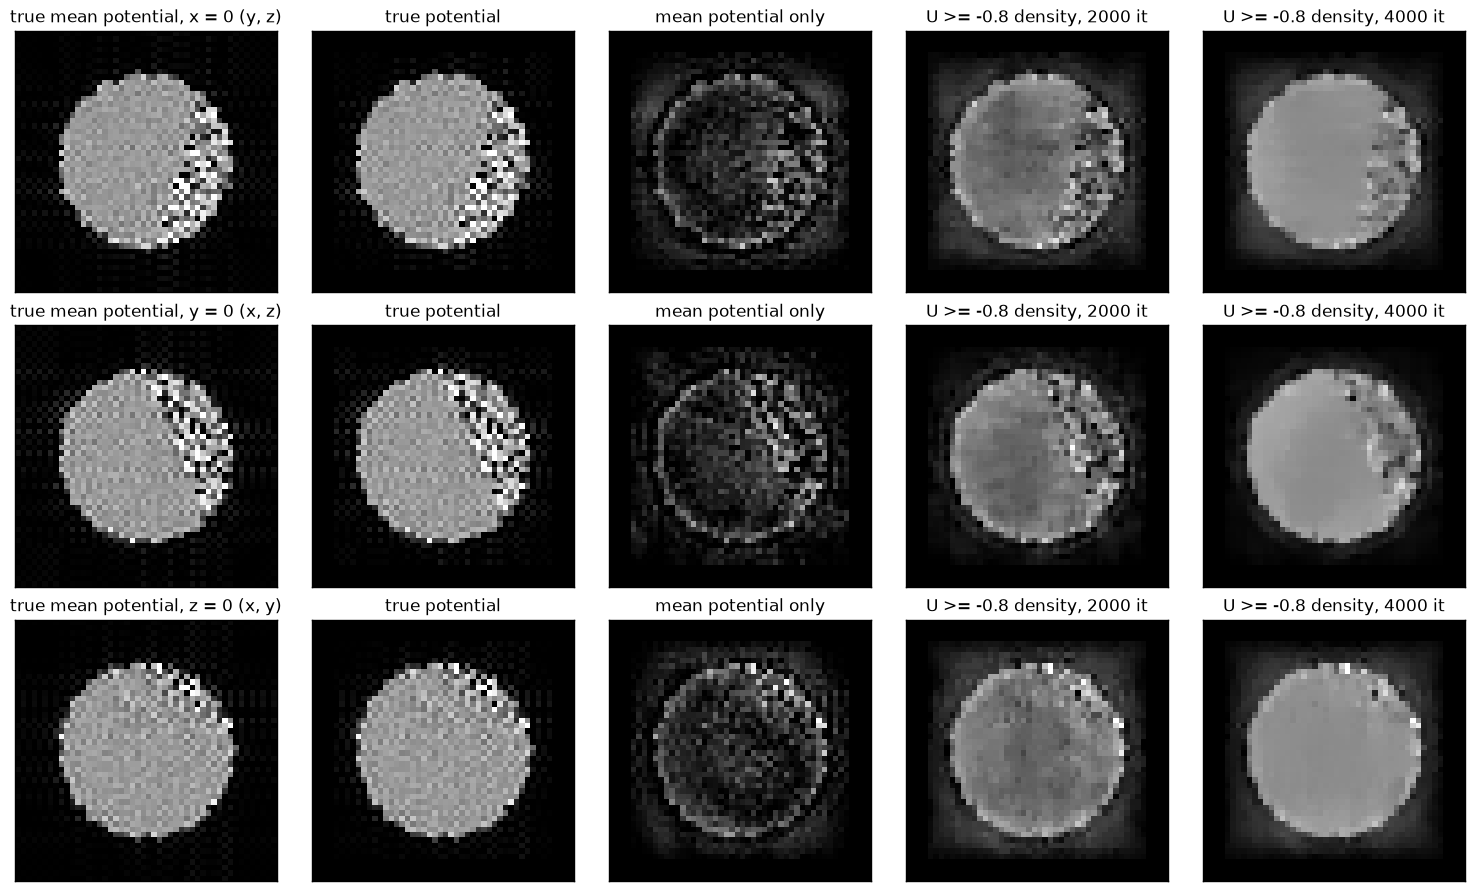

In [5]:
k = vt.shape[0] // 2
slices = lambda v: [v[k], v[:, k], v[:, :, k]]
labels = ["x = 0 (y, z)", "y = 0 (x, z)", "z = 0 (x, y)"]
cols = list(r)
show_2d(
    [[s] + [slices(r[n]["vbar"])[i] for n in cols] for i, s in enumerate(slices(vt))],
    norm={"interval_type": "manual", "vmin": 0.0, "vmax": 0.04},
    cmap="gray",
    title=[[f"true mean potential, {labels[i]}"] + cols for i in range(3)],
    axsize=(3, 3),
);

## Tilt-series movies
Data on the left, model on the right, one fixed gray scale for both and for every tilt. Both are band-limited the same way (`band_limit`: round, smooth taper from half the Nyquist frequency), which removes the pixel checkerboard. The central 128 A of the field of view, tilt axis vertical. Saved to `runs/movie_twinAm_x2_<case>.mp4`.

In [6]:
crop = slice(n // 2 - n // 3, n // 2 + n // 3)
frames = lambda a: np.transpose(band_limit(a).numpy()[:, crop, crop], (0, 2, 1))
vmin, vmax = np.percentile(frames(data), [0.1, 99.9])
movies = {}
for name, case in cases.items():
    label = lambda t: [f"data, {ang[t]:+.0f} deg", "model, held out" if t in held else "model"]
    movies[name] = save_movie([frames(data), frames(r[name]["pred"])], label, f"runs/movie_twinAm_x2_{case}.mp4", vmin, vmax)

Model: sub-blocks with U >= -0.8 density, 4000 iterations.

In [7]:
display(Video(movies["U >= -0.8 density, 4000 it"], embed=True, width=800))

Model: mean potential only.

In [8]:
display(Video(movies["mean potential only"], embed=True, width=800))